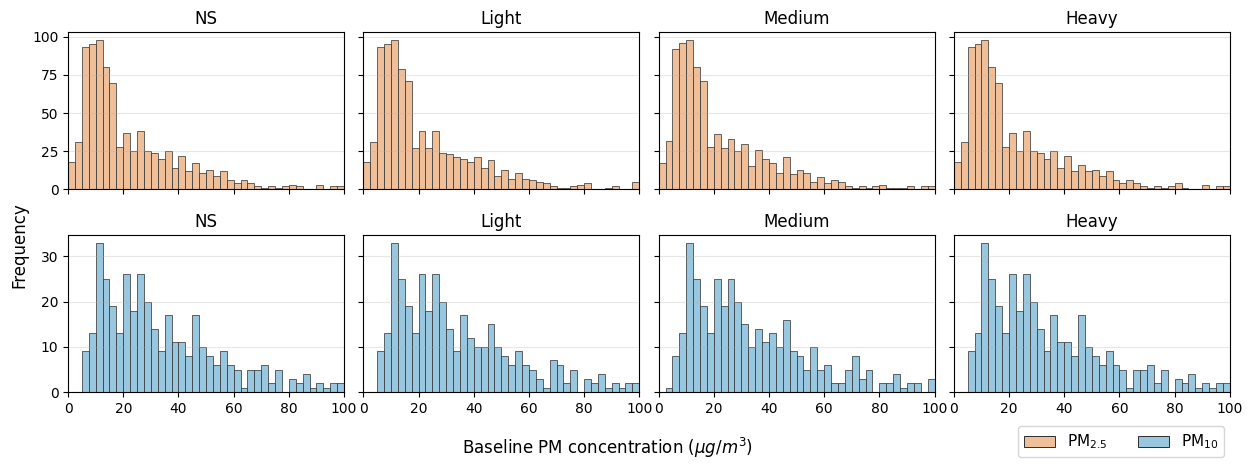

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

PM25_LIGHT50, PM10_LIGHT50 = "#EEBF99", "#99C7E0"
box_and_whisker_boundary = "#2C2D2D"

label_map = {0: "NS", 1: "Light", 2: "Medium", 3: "Heavy"}

pm10 = pd.read_csv(
    r"\results\pm10\PM10_smoke_matched_df_overall_cv6_rnd42_k1.csv"
)

pm25 = pd.read_csv(
    r"\results\pm25\PM25_smoke_matched_df_overall_cv6_rnd42_k1.csv"
)

pm10 = pm10.dropna(subset=["Density", "prev_pm"]).copy()
pm25 = pm25.dropna(subset=["Density", "prev_pm"]).copy()

densities = [0, 1, 2, 3]

fig, axes = plt.subplots(2, 4, figsize=(13, 5), sharex=True, sharey=False)

for j, d in enumerate(densities):
    vals = pm25.loc[pm25["Density"] == d, "prev_pm"].dropna()

    axes[0, j].hist(
        vals,
        bins=40,
        range=(0, 100),
        color=PM25_LIGHT50,
        edgecolor=box_and_whisker_boundary,
        linewidth=0.5
    )

    axes[0, j].set_xlim(0, 100)
    axes[0, j].set_title(f"{label_map[d]}", fontsize=12)
    axes[0, j].grid(axis="y", alpha=0.3)

for j, d in enumerate(densities):
    vals = pm10.loc[pm10["Density"] == d, "prev_pm"].dropna()

    axes[1, j].hist(
        vals,
        bins=40,
        range=(0, 100),
        color=PM10_LIGHT50,
        edgecolor=box_and_whisker_boundary,
        linewidth=0.5
    )

    axes[1, j].set_xlim(0, 100)
    axes[1, j].set_title(f"{label_map[d]}", fontsize=12)
    axes[1, j].grid(axis="y", alpha=0.3)

for ax in axes[:, 1:].flatten():
    ax.tick_params(axis="y", labelleft=False)

fig.supxlabel(r"Baseline PM concentration ($\mu g/m^3$)", fontsize=12, y=0.07)
fig.supylabel("Frequency", fontsize=12, x=0.04)

legend_handles = [
    Patch(
        facecolor=PM25_LIGHT50,
        edgecolor=box_and_whisker_boundary,
        linewidth=0.7,
        label=r"PM$_{2.5}$"
    ),
    Patch(
        facecolor=PM10_LIGHT50,
        edgecolor=box_and_whisker_boundary,
        linewidth=0.7,
        label=r"PM$_{10}$"
    )
]

fig.legend(
    handles=legend_handles,
    loc="lower right",
    bbox_to_anchor=(0.98, 0.06),
    ncol=2,
    frameon=True,
    fontsize=11
)

plt.tight_layout(rect=[0.02, 0.05, 1, 1])
fig.subplots_adjust(wspace=0.07)

plt.savefig(
    r"\figures\smoke_baseline_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
